#Intro

In [ ]:
import pandas as pd
!pip install fairlearn
from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, roc_auc_score
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score

from fairlearn.metrics import (MetricFrame,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference,
    equalized_odds_ratio, selection_rate
)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.0/240.0 kB 4.4 MB/s eta 0:00:00


In [ ]:
df = pd.read_csv('/content/sample_data/combined_with_theoretical_region.csv')

In [ ]:
# prompt: apply smote on df to fix class imbalance

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Assuming 'target_column' is the name of your target variable column
X = df.drop('target', axis=1)
y = df['target']


smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)


df_resampled = pd.DataFrame(X_resampled, columns=X.columns)
df_resampled['target'] = y_resampled

df = df_resampled.copy()

In [ ]:
df['target'].value_counts()

,count
target,
0,508
1,508


In [ ]:
df['Cluster_region'].value_counts()

,count
Cluster_region,
2,392
1,278
0,198
3,148


In [ ]:
df.to_csv('combined_with_theoretical_region_SMOTE.csv',index=False)

# Clinical

## XGBOOST Gender

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd
df = pd.read_csv('/content/combined_statslogExcluded_SMOTE.csv')
X = df.drop('target',axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=123,stratify=y)
df

In [ ]:
X_test.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope'],
      dtype='object')

In [ ]:
import xgboost as xgb

xgb_clf = xgb.XGBClassifier(
    objective="binary:logistic",  # or "multi:softprob" for multiclass
    eval_metric="logloss",        # can be "mlogloss" or "auc" based on task
    use_label_encoder=False,
    n_estimators = 115, max_depth = 6, learning_rate = 0.0547, subsample = 0.5715,
    colsample_bytree = 0.5422, gamma = 1.5894, reg_alpha = 0.9968, reg_lambda = 0.8258
)

xgb_clf.fit(X_train, y_train)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [09:50:46] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.5422, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=1.5894, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.0547, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=115,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [ ]:


# Simulated example:
y_true = y_test.copy()
y_pred = xgb_clf.predict(X_test)
sensitive_features = X_test['sex']  # 0: Female, 1: Male

print(classification_report(y_pred, y_test))
print('BIAS METRICS SHOWN BELOW')
# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



              precision    recall  f1-score   support

           0       0.89      0.92      0.91        99
           1       0.92      0.90      0.91       105

    accuracy                           0.91       204
   macro avg       0.91      0.91      0.91       204
weighted avg       0.91      0.91      0.91       204

BIAS METRICS SHOWN BELOW
Group-wise metrics:
     accuracy  selection_rate  precision    recall
sex                                               
0    0.907407        0.222222   0.750000  0.818182
1    0.906667        0.620000   0.913978  0.934066

Demographic parity difference: 0.3977777777777778
Demographic parity ratio: 0.35842293906810035

Equalized odds difference: 0.11588411588411585
Equalized odds ratio: 0.5145348837209303


In [ ]:
mf.by_group['selection_rate'].plot(kind='bar', title='Selection Rate by Sex')


In [ ]:
print("Heart disease prevalence (by sex):")
print(y_train.groupby(X_train["sex"]).mean())


Heart disease prevalence (by sex):
sex
0    0.204188
1    0.590982
Name: target, dtype: float64


In [ ]:
female = 0.2041
male = 0.5909

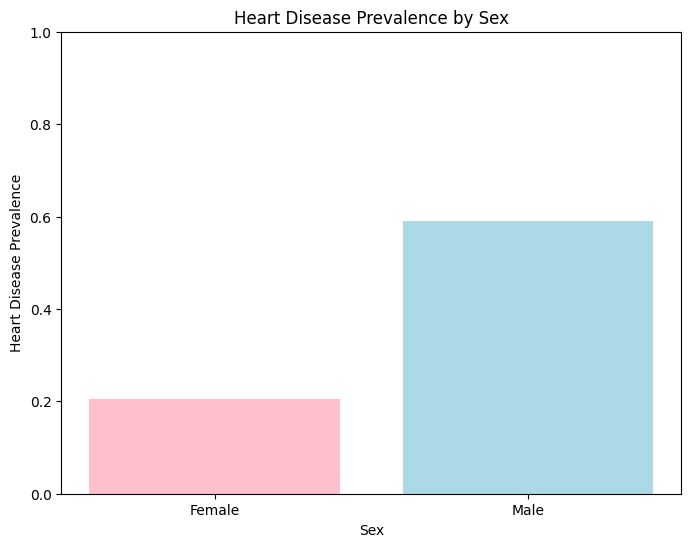

In [ ]:
# prompt: make a bar chart on female and male

import matplotlib.pyplot as plt

female = 0.2041
male = 0.5909

# Data for plotting
sexes = ['Female', 'Male']
prevalence = [female, male]

# Create the bar chart
plt.figure(figsize=(8, 6))  # Adjust figure size if needed
plt.bar(sexes, prevalence, color=['pink', 'lightblue'])
plt.xlabel('Sex')
plt.ylabel('Heart Disease Prevalence')
plt.title('Heart Disease Prevalence by Sex')
plt.ylim(0, 1)  # Set y-axis limits for better visualization
plt.show()


In [ ]:
print("Heart disease prevalence (by Region):")
print(y_train.groupby(X_train["Cluster_region"]).mean())


## XGBOOST REGION [Generalization purposes]

In [ ]:
df = pd.read_csv('/content/combined_with_theoretical_region_SMOTE.csv')
X = df.drop('target',axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=123,stratify=y)
df

In [ ]:


xgb_clf = xgb.XGBClassifier(
    objective="binary:logistic",  # or "multi:softprob" for multiclass
    eval_metric="logloss",        # can be "mlogloss" or "auc" based on task
    use_label_encoder=False,
    n_estimators = 115, max_depth = 6, learning_rate = 0.0547, subsample = 0.5715,
    colsample_bytree = 0.5422, gamma = 1.5894, reg_alpha = 0.9968, reg_lambda = 0.8258
)

xgb_clf.fit(X_train, y_train)


Heart disease prevalence (by Region):
Cluster_region
0    0.839161
1    0.795349
2    0.138983
3    0.449541
Name: target, dtype: float64


In [ ]:
heart_disease_prevalence = {'T_Long Beach VA[0]':0.8391, 'T_Hungary[1]': 0.7953, 'T_Cleveland[2]': 0.1389, 'T_Switzerland[3]': 0.4495}

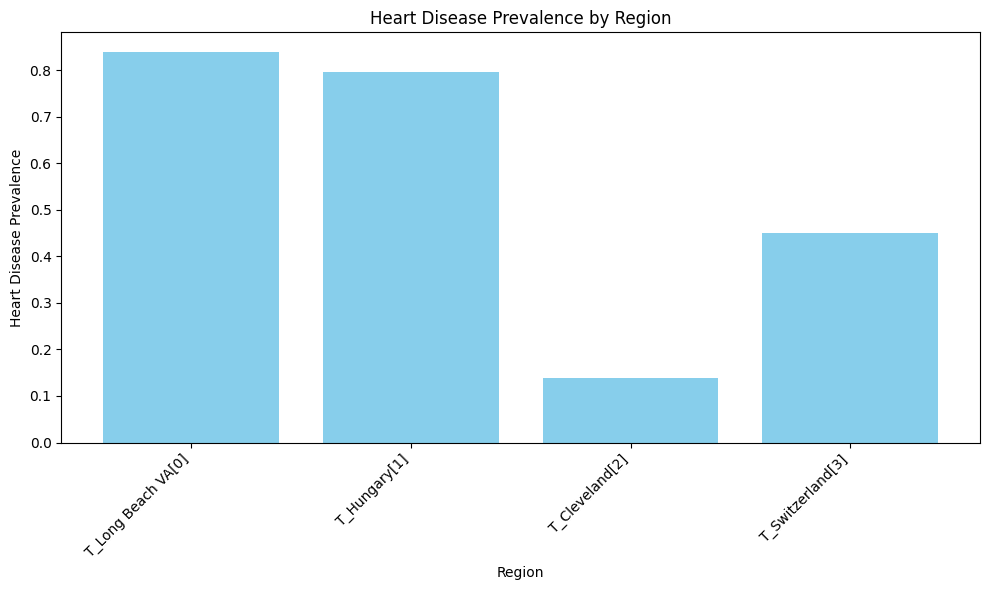

In [ ]:
# prompt: make bar plot of heart_disease_prevalence

import matplotlib.pyplot as plt

heart_disease_prevalence = {'T_Long Beach VA[0]':0.8391, 'T_Hungary[1]': 0.7953, 'T_Cleveland[2]': 0.1389, 'T_Switzerland[3]': 0.4495}

regions = list(heart_disease_prevalence.keys())
prevalence_rates = list(heart_disease_prevalence.values())

plt.figure(figsize=(10, 6))
plt.bar(regions, prevalence_rates, color='skyblue')
plt.xlabel("Region")
plt.ylabel("Heart Disease Prevalence")
plt.title("Heart Disease Prevalence by Region")
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()
plt.show()


In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn
from sklearn.metrics import accuracy_score, precision_score, recall_score

from fairlearn.metrics import (MetricFrame,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference,
    equalized_odds_ratio, selection_rate
)

import pandas as pd

# Simulated example:
y_true = y_test.copy()
y_pred = xgb_clf.predict(X_test)
sensitive_features = X_test['Cluster_region']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
                accuracy  selection_rate  precision  recall
Cluster_region                                             
0               0.945455        0.927273   0.960784  0.9800
1               0.888889        0.920635   0.879310  1.0000
2               0.927835        0.072165   0.714286  0.5000
3               0.794872        0.461538   0.722222  0.8125

Demographic parity difference: 0.855107778819119
Demographic parity ratio: 0.077824944410754

Equalized odds difference: 0.560344827586207
Equalized odds ratio: 0.039408866995073885


## LGBoost Gender

In [ ]:

df = pd.read_csv('/content/combined_statslogExcluded_SMOTE.csv')
X = df.drop('target',axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=123,stratify=y)
df

In [ ]:

# 1. Initialize the model
lgbm_clf = LGBMClassifier(n_estimators=125, max_depth=3, learning_rate=0.0360, subsample=0.5064,
                          colsample_bytree=0.5004, num_leaves=108, min_child_samples=21, reg_alpha=0.8659,
                          reg_lambda=0.6940, verbose=-1)

lgbm_clf.fit(X_train, y_train)

In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn

# Simulated example:
y_true = y_test.copy()
y_pred = lgbm_clf.predict(X_test)
sensitive_features = X_test['sex']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
     accuracy  selection_rate  precision    recall
sex                                               
0    0.878788        0.242424   0.687500  0.785714
1    0.877660        0.627660   0.881356  0.920354

Demographic parity difference: 0.38523533204384264
Demographic parity ratio: 0.38623523369286084

Equalized odds difference: 0.13463969658659924
Equalized odds ratio: 0.5151098901098902


## LGBoost Region [GENERALIZATION Purpose]

In [ ]:
df = pd.read_csv('/content/combined_with_theoretical_region_SMOTE.csv')
X = df.drop('target',axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=123,stratify=y)
df

In [ ]:

# 1. Initialize the model
lgbm_clf = LGBMClassifier(n_estimators=125, max_depth=3, learning_rate=0.0360, subsample=0.5064,
                          colsample_bytree=0.5004, num_leaves=108, min_child_samples=21, reg_alpha=0.8659,
                          reg_lambda=0.6940, verbose=-1)

lgbm_clf.fit(X_train, y_train)

LGBMClassifier(colsample_bytree=0.5004, learning_rate=0.036, max_depth=3,
               min_child_samples=21, n_estimators=125, num_leaves=108,
               reg_alpha=0.8659, reg_lambda=0.694, subsample=0.5064,
               verbose=-1)

In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn


# Simulated example:
y_true = y_test.copy()
y_pred = lgbm_clf.predict(X_test)
sensitive_features = X_test['Cluster_region']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
                accuracy  selection_rate  precision  recall
Cluster_region                                             
0               0.945455        0.927273   0.960784  0.9800
1               0.873016        0.936508   0.864407  1.0000
2               0.927835        0.051546   0.800000  0.4000
3               0.820513        0.435897   0.764706  0.8125

Demographic parity difference: 0.8849615447553592
Demographic parity ratio: 0.05504106237987069

Equalized odds difference: 0.6551724137931034
Equalized odds ratio: 0.017241379310344827


## RF Gender

In [ ]:
df = pd.read_csv('/content/combined_statslogExcluded_SMOTE.csv')
X = df.drop('target',axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=123,stratify=y)
df

In [ ]:

rfc_clf = RandomForestClassifier(n_estimators=256, max_depth=14, min_samples_split=7, min_samples_leaf=1,
                                 max_features='sqrt',bootstrap=True)
rfc_clf.fit(X_train, y_train)

In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn

# Simulated example:
y_true = y_test.copy()
y_pred = rfc_clf.predict(X_test)
sensitive_features = X_test['sex']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
     accuracy  selection_rate  precision    recall
sex                                               
0    0.924242        0.227273   0.800000  0.857143
1    0.861702        0.632979   0.865546  0.911504

Demographic parity difference: 0.405705996131528
Demographic parity ratio: 0.35905271199388844

Equalized odds difference: 0.15564102564102567
Equalized odds ratio: 0.2704326923076923


## RF Region [Generalization]

In [ ]:
df = pd.read_csv('/content/combined_with_theoretical_region_SMOTE.csv')
X = df.drop('target',axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=123,stratify=y)
df

In [ ]:

rfc_clf = RandomForestClassifier(n_estimators=256, max_depth=14, min_samples_split=7, min_samples_leaf=1,
                                 max_features='sqrt',bootstrap=True)
rfc_clf.fit(X_train, y_train)

RandomForestClassifier(max_depth=14, min_samples_split=7, n_estimators=256)

In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn


# Simulated example:
y_true = y_test.copy()
y_pred = rfc_clf.predict(X_test)
sensitive_features = X_test['Cluster_region']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
                accuracy  selection_rate  precision    recall
Cluster_region                                               
0               0.945455        0.927273   0.960784  0.980000
1               0.873016        0.904762   0.877193  0.980392
2               0.938144        0.082474   0.750000  0.600000
3               0.794872        0.461538   0.722222  0.812500

Demographic parity difference: 0.8447985004686035
Demographic parity ratio: 0.08894279361229028

Equalized odds difference: 0.560344827586207
Equalized odds ratio: 0.039408866995073885


## Bias Mitigation for The Best Model XGBOOST

In [ ]:

xgb_clf = xgb.XGBClassifier(
    objective="binary:logistic",  # or "multi:softprob" for multiclass
    eval_metric="logloss",        # can be "mlogloss" or "auc" based on task
    use_label_encoder=False,
    n_estimators = 115, max_depth = 6, learning_rate = 0.0547, subsample = 0.5715,
    colsample_bytree = 0.5422, gamma = 1.5894, reg_alpha = 0.9968, reg_lambda = 0.8258
)

xgb_clf.fit(X_train, y_train)
y_proba = xgb_clf.predict_proba(X_test)[:, 1]


In [ ]:
# Create the ThresholdOptimizer
postprocessor = ThresholdOptimizer(
    estimator=xgb_clf,
    constraints="equalized_odds",  # or "equalized_odds"
    predict_method="predict_proba",
    prefit=True  # since the classifier is already fitted
)

# Fit the postprocessor on the test set
postprocessor.fit(
    X_test,
    y_test,
    sensitive_features=X_test["sex"]  # or your sensitive feature
)


In [ ]:
# Predict using the fair postprocessor
y_pred_fair = postprocessor.predict(X_test, sensitive_features=X_test["sex"])

# Print classification report
print("Classification Report:\n", classification_report(y_test, y_pred_fair))

In [ ]:


# Compute group-wise metrics
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'precision': precision_score,
        'recall': recall_score,
        'selection_rate': selection_rate
    },
    y_true=y_test,
    y_pred=y_pred_fair,
    sensitive_features=X_test["sex"]
)

# Print the group-wise metric matrix
print("Group-wise fairness metrics:")
print(mf.by_group)


# Demographic Parity metrics
dp_diff = demographic_parity_difference(y_test, y_pred_fair, sensitive_features=X_test["sex"])
dp_ratio = demographic_parity_ratio(y_test, y_pred_fair, sensitive_features=X_test["sex"])

print("\nDemographic Parity Difference:", dp_diff)
print("Demographic Parity Ratio:", dp_ratio)

# Equalized Odds metrics
eo_diff = equalized_odds_difference(y_test, y_pred_fair, sensitive_features=X_test["sex"])
eo_ratio = equalized_odds_ratio(y_test, y_pred_fair, sensitive_features=X_test["sex"])

print("\nEqualized Odds Difference:", eo_diff)
print("Equalized Odds Ratio:", eo_ratio)


# Non-clinical

## XGBoost Gender

In [ ]:
df = pd.read_csv('/content/combined_statslogExcluded_SMOTE.csv')
region_df = pd.read_csv('/content/combined_with_theoretical_region_SMOTE.csv')

In [ ]:
reduced_df = df.drop(columns=['chol','restecg','slope', 'oldpeak'],axis=1)
X = reduced_df.drop('target',axis=1)
y = reduced_df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=y,random_state=123)

In [ ]:
import xgboost as xgb

xgb_clf = xgb.XGBClassifier(
    objective="binary:logistic",  # or "multi:softprob" for multiclass
    eval_metric="logloss",        # can be "mlogloss" or "auc" based on task
    use_label_encoder=False,
    n_estimators = 153, max_depth = 3, learning_rate = 0.2017, subsample = 0.94,
    colsample_bytree = 0.9488, gamma = 3.5160, reg_alpha = 0.7811, reg_lambda = 0.6871
)

xgb_clf.fit(X_train, y_train)


In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn
from sklearn.metrics import accuracy_score, precision_score, recall_score

from fairlearn.metrics import (MetricFrame,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference,
    equalized_odds_ratio, selection_rate
)

import pandas as pd

# Simulated example:
y_true = y_test.copy()
y_pred = xgb_clf.predict(X_test)
sensitive_features = X_test['sex']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
     accuracy  selection_rate  precision    recall
sex                                               
0    0.878788        0.181818   0.750000  0.642857
1    0.803191        0.627660   0.822034  0.858407

Demographic parity difference: 0.44584139264990325
Demographic parity ratio: 0.28967642526964565

Equalized odds difference: 0.22230769230769232
Equalized odds ratio: 0.20604395604395603


## XGBoost Region

In [ ]:
reduced_df = region_df.drop(columns=['chol','restecg','slope', 'oldpeak'],axis=1)
X = reduced_df.drop('target',axis=1)
y = reduced_df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=y,random_state=123)


In [ ]:
import xgboost as xgb

xgb_clf = xgb.XGBClassifier(
    objective="binary:logistic",  # or "multi:softprob" for multiclass
    eval_metric="logloss",        # can be "mlogloss" or "auc" based on task
    use_label_encoder=False,
    n_estimators = 153, max_depth = 3, learning_rate = 0.2017, subsample = 0.94,
    colsample_bytree = 0.9488, gamma = 3.5160, reg_alpha = 0.7811, reg_lambda = 0.6871
)

xgb_clf.fit(X_train, y_train)


In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn
from sklearn.metrics import accuracy_score, precision_score, recall_score

from fairlearn.metrics import (MetricFrame,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference,
    equalized_odds_ratio, selection_rate
)

import pandas as pd

# Simulated example:
y_true = y_test.copy()
y_pred = xgb_clf.predict(X_test)
sensitive_features = X_test['Cluster_region']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
                accuracy  selection_rate  precision    recall
Cluster_region                                               
0               0.909091        0.890909   0.959184  0.940000
1               0.857143        0.888889   0.875000  0.960784
2               0.876289        0.041237   0.250000  0.100000
3               0.666667        0.435897   0.588235  0.625000

Demographic parity difference: 0.849671977507029
Demographic parity ratio: 0.046286555859457186

Equalized odds difference: 0.8607843137254902
Equalized odds ratio: 0.059113300492610835


## LGBoost gender

In [ ]:
reduced_df = df.drop(columns=['chol','restecg','slope', 'oldpeak'],axis=1)
X = reduced_df.drop('target',axis=1)
y = reduced_df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=y,random_state=123)


In [ ]:
lgbm_clf = LGBMClassifier(n_estimators=87, max_depth=3, learning_rate=0.0824, subsample=0.6705,
                          colsample_bytree=0.5497, num_leaves=150, min_child_samples=7, reg_alpha=0.9817,
                          reg_lambda=0.7483, verbose=-1)

# 2. Fit the model
lgbm_clf.fit(X_train, y_train)


In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn

# Simulated example:
y_true = y_test.copy()
y_pred = lgbm_clf.predict(X_test)
sensitive_features = X_test['sex']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
     accuracy  selection_rate  precision    recall
sex                                               
0    0.878788        0.151515   0.800000  0.571429
1    0.819149        0.622340   0.837607  0.867257

Demographic parity difference: 0.47082527401676344
Demographic parity ratio: 0.24346024346024345

Equalized odds difference: 0.2958280657395702
Equalized odds ratio: 0.15182186234817813


## LGBoost region

In [ ]:
reduced_df = region_df.drop(columns=['chol','restecg','slope', 'oldpeak'],axis=1)
X = reduced_df.drop('target',axis=1)
y = reduced_df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=y,random_state=123)
X

In [ ]:
lgbm_clf = LGBMClassifier(n_estimators=87, max_depth=3, learning_rate=0.0824, subsample=0.6705,
                          colsample_bytree=0.5497, num_leaves=150, min_child_samples=7, reg_alpha=0.9817,
                          reg_lambda=0.7483, verbose=-1)

# 2. Fit the model
lgbm_clf.fit(X_train, y_train)


In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn


# Simulated example:
y_true = y_test.copy()
y_pred = lgbm_clf.predict(X_test)
sensitive_features = X_test['Cluster_region']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
                accuracy  selection_rate  precision    recall
Cluster_region                                               
0               0.909091        0.890909   0.959184  0.940000
1               0.841270        0.841270   0.886792  0.921569
2               0.876289        0.041237   0.250000  0.100000
3               0.717949        0.487179   0.631579  0.750000

Demographic parity difference: 0.849671977507029
Demographic parity ratio: 0.046286555859457186

Equalized odds difference: 0.84
Equalized odds ratio: 0.06896551724137931


## RF Gender

In [ ]:
reduced_df = df.drop(columns=['chol','restecg','slope', 'oldpeak'],axis=1)
X = reduced_df.drop('target',axis=1)
y = reduced_df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=y,random_state=123)
X

In [ ]:
rfc_clf = RandomForestClassifier(n_estimators=110, max_depth=20, min_samples_split=4, min_samples_leaf=8,
                                 max_features='sqrt',bootstrap=True)
rfc_clf.fit(X_train, y_train)

In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn

# Simulated example:
y_true = y_test.copy()
y_pred = rfc_clf.predict(X_test)
sensitive_features = X_test['sex']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
     accuracy  selection_rate  precision    recall
sex                                               
0    0.893939         0.19697   0.769231  0.714286
1    0.835106         0.62766   0.847458  0.884956

Demographic parity difference: 0.4306898774983881
Demographic parity ratio: 0.3138161273754494

Equalized odds difference: 0.18230769230769228
Equalized odds ratio: 0.24038461538461542


## RF Region

In [ ]:
reduced_df = region_df.drop(columns=['chol','restecg','slope', 'oldpeak'],axis=1)
X = reduced_df.drop('target',axis=1)
y = reduced_df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,stratify=y,random_state=123)
X

In [ ]:
rfc_clf = RandomForestClassifier(n_estimators=110, max_depth=20, min_samples_split=4, min_samples_leaf=8,
                                 max_features='sqrt',bootstrap=True)
rfc_clf.fit(X_train, y_train)

In [ ]:
# ✅ Install if not already installed
# !pip install fairlearn


# Simulated example:
y_true = y_test.copy()
y_pred = rfc_clf.predict(X_test)
sensitive_features = X_test['Cluster_region']  # 0: Female, 1: Male

# ➤ Create the fairness metrics frame
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'selection_rate': selection_rate,
        'precision': precision_score,
        'recall': recall_score
    },
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=sensitive_features
)

print("Group-wise metrics:")
print(mf.by_group)

# ➤ Fairness differences and ratios
dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)

eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)
eo_ratio = equalized_odds_ratio(y_true, y_pred, sensitive_features=sensitive_features)

print("\nDemographic parity difference:", dp_diff)
print("Demographic parity ratio:", dp_ratio)

print("\nEqualized odds difference:", eo_diff)
print("Equalized odds ratio:", eo_ratio)



Group-wise metrics:
                accuracy  selection_rate  precision    recall
Cluster_region                                               
0               0.909091        0.890909   0.959184  0.940000
1               0.857143        0.888889   0.875000  0.960784
2               0.876289        0.020619   0.000000  0.000000
3               0.717949        0.333333   0.692308  0.562500

Demographic parity difference: 0.8702905342080599
Demographic parity ratio: 0.023143277929728593

Equalized odds difference: 0.9607843137254902
Equalized odds ratio: 0.0


## Bias mitigation for RF Non-clinical

In [ ]:
rfc_clf = RandomForestClassifier(n_estimators=110, max_depth=20, min_samples_split=4, min_samples_leaf=8,
                                 max_features='sqrt',bootstrap=True)
rfc_clf.fit(X_train, y_train)
y_proba = rfc_clf.predict_proba(X_test)[:, 1]


In [ ]:
# Create the ThresholdOptimizer
postprocessor = ThresholdOptimizer(
    estimator=rfc_clf,
    constraints="equalized_odds",  # or "equalized_odds"
    predict_method="predict_proba",
    prefit=True  # since the classifier is already fitted
)

# Fit the postprocessor on the test set
postprocessor.fit(
    X_test,
    y_test,
    sensitive_features=X_test["sex"]  # or your sensitive feature
)


ThresholdOptimizer(constraints='equalized_odds',
                   estimator=RandomForestClassifier(max_depth=20,
                                                    min_samples_leaf=8,
                                                    min_samples_split=4,
                                                    n_estimators=110),
                   predict_method='predict_proba', prefit=True)

In [ ]:
# Predict using the fair postprocessor
y_pred_fair = postprocessor.predict(X_test, sensitive_features=X_test["sex"])

# Print classification report
print("Classification Report:\n", classification_report(y_test, y_pred_fair))

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.80      0.83       127
           1       0.81      0.87      0.84       127

    accuracy                           0.83       254
   macro avg       0.84      0.83      0.83       254
weighted avg       0.84      0.83      0.83       254



In [ ]:


# Compute group-wise metrics
mf = MetricFrame(
    metrics={
        'accuracy': accuracy_score,
        'precision': precision_score,
        'recall': recall_score,
        'selection_rate': selection_rate
    },
    y_true=y_test,
    y_pred=y_pred_fair,
    sensitive_features=X_test["sex"]
)

# Print the group-wise metric matrix
print("Group-wise fairness metrics:")
print(mf.by_group)


# Demographic Parity metrics
dp_diff = demographic_parity_difference(y_test, y_pred_fair, sensitive_features=X_test["sex"])
dp_ratio = demographic_parity_ratio(y_test, y_pred_fair, sensitive_features=X_test["sex"])

print("\nDemographic Parity Difference:", dp_diff)
print("Demographic Parity Ratio:", dp_ratio)

# Equalized Odds metrics
eo_diff = equalized_odds_difference(y_test, y_pred_fair, sensitive_features=X_test["sex"])
eo_ratio = equalized_odds_ratio(y_test, y_pred_fair, sensitive_features=X_test["sex"])

print("\nEqualized Odds Difference:", eo_diff)
print("Equalized Odds Ratio:", eo_ratio)


Group-wise fairness metrics:
     accuracy  precision    recall  selection_rate
sex                                               
0    0.833333   0.571429  0.857143        0.318182
1    0.835106   0.853448  0.876106        0.617021

Demographic Parity Difference: 0.2988394584139265
Demographic Parity Ratio: 0.5156739811912225

Equalized Odds Difference: 0.05358974358974358
Equalized Odds Ratio: 0.7635746606334842


# Next: Bias Mitigation with Data Augmentation
## ThresholdOptimizer comes up with cost. So, balancing gender data frequency by data augmentation can be a robust approach:
: https://colab.research.google.com/drive/17zliIkXw4MlEyH696gB8UzZKju_ohdQg?usp=sharing

# About regional bias: it probably happens due to one region closely resembling others. Lets check out:https://colab.research.google.com/drive/1eQ3kwMdNflD6z9WryG_vYmR705CqribC?usp=sharing
